# Week 3 · Budget-constrained email allocation

**Question:** Which customers should receive Men’s Email, Women’s Email, or No Email to maximize predicted extra revenue within a fixed budget?

This continues notebook 06. The project guide explicitly maps discounts to email actions for Hillstrom. We cannot recommend $10/$20 discounts from this dataset. No messages are sent by this notebook.

Run cells in order using the project Python environment. This notebook uses the committed dashboard snapshot from notebooks 01–06, so a fresh clone works without retraining. After a new model run, execute `python dashboard/export_data.py` **before** rerunning this notebook. The chosen snapshot and raw-data hashes are recorded.

Week 3 deliverables: SciPy optimizer, budget checks, benchmarks, allocation CSV, React allocation view. Week 4 remains REST API, drift detection and final packaging.


In [1]:
from pathlib import Path
from decimal import Decimal
import hashlib
import json
import itertools
import time
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import linprog
from scipy.sparse import csc_matrix
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'dashboard/public/results/report.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this repository as your VS Code folder.')
PUBLIC = ROOT / 'dashboard/public/results'
OUTPUT = ROOT / 'results/optimization'
OUTPUT.mkdir(parents=True, exist_ok=True)
report = json.loads((PUBLIC / 'report.json').read_text())
score_path = PUBLIC / 'customer_scores.csv'
scores = pd.read_csv(score_path)
raw_path = ROOT / 'data/raw/hillstrom.csv'
raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()
assert raw_hash == report['source_sha256'] == report['model_info']['raw_sha256']
assert len(scores) == report['eda']['rows'] == 64000
assert scores.customer_id.is_unique
assert (scores.split == 'test').sum() == report['model_info']['test_rows'] == 19200
assert np.isfinite(scores[['spend_mens', 'spend_womens']].to_numpy()).all()
assert max(c['maximum_export_error'] for c in report['exact_model_checks']) < 1e-9
print('Loaded 64,000 previously audited score rows; 19,200 held out from model training.')
print('Spending ranking advantage remains uncertain for BOTH email types.')
print('The women’s visit audit also has a subset stability warning.')

Loaded 64,000 previously audited score rows; 19,200 held out from model training.
Spending ranking advantage remains uncertain for BOTH email types.
The women’s visit audit also has a subset stability warning.


## 1. State the decision and assumptions

Let x(i,a) be 1 when customer i receives email a, otherwise 0. Maximize **sum(predicted spending effect × x)**, subject to:

- At most one email per customer; no email costs zero and has zero incremental effect.
- Total email cost does not exceed the budget.
- Every decision is a whole customer (0 or 1).

Both email types cost the same assumed amount, so choose each customer's better email first, then choose which customers fit the budget. This reduces two variables per customer to one without changing the optimum. With equal costs, the constraint is an integer contact limit; the linear program has integral vertices. We check that returned decisions are 0/1 rather than blindly rounding a general linear program. SciPy linear programming solves this special case with whole-customer decisions; an independent top-K calculation checks the objective and resolves ties reproducibly.

**Important:** This maximizes predicted extra revenue, not net profit. We also show revenue minus assumed email costs, but product margins and other costs are unknown. Positive predicted effects are not proof that someone is a persuadable customer. Spending was a secondary outcome with uncertain held-out ranking evidence.

Costs are user assumptions (default $0.10), not observed costs. Integer cents enforce a strict budget. The simple browser optimizer is exact only for equal email costs and no other constraints.


In [2]:
def cents(value, name, positive=False):
    """Keep the budget exact: dollar inputs must have at most two decimals."""
    amount = Decimal(str(value))
    if not amount.is_finite() or amount < 0 or (positive and amount == 0):
        raise ValueError(f'{name} must be finite and {"positive" if positive else "nonnegative"}.')
    scaled = amount * 100
    if scaled != scaled.to_integral_value():
        raise ValueError(f'{name} must have at most two decimal places.')
    if scaled > 100_000_000_000:
        raise ValueError(f'{name} is too large.')
    return int(scaled)


def allocate_email(rows, budget=5000, email_cost=0.10):
    """Maximize predicted incremental spend; one email or no email per row.

    Both email types have the same user-assumed cost. For each customer we
    can first choose the better email, then solve a cardinality linear program.
    This reduction is exact ONLY for equal action costs and no extra constraints.
    """
    budget_cents = cents(budget, 'Budget')
    cost_cents = cents(email_cost, 'Email cost', positive=True)
    required = ['customer_id', 'spend_mens', 'spend_womens']
    if not set(required).issubset(rows.columns):
        raise ValueError('Missing customer_id or spending effect columns.')
    if rows.customer_id.isna().any() or not rows.customer_id.is_unique:
        raise ValueError('Customer IDs must be present and unique.')
    values = rows[['spend_mens', 'spend_womens']].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Spending effects must be finite.')
    result = rows.copy().reset_index(drop=True)
    best = values.max(axis=1) if len(rows) else np.array([])
    best_arm = np.where(values[:, 0] >= values[:, 1], 'Mens E-Mail', 'Womens E-Mail')
    capacity = min(len(rows), budget_cents // cost_cents)
    eligible = np.flatnonzero(best > 0)
    chosen = np.zeros(len(rows), dtype=bool)
    solver_message, gap = 'No positive affordable action; no email selected.', 0.0
    if capacity and len(eligible):
        # Binary z_i: send the customer's better email (1) or no email (0).
        # Minimize the negative effect because scipy.optimize.linprog minimizes.
        # The unit-cost cardinality constraint has an integral polytope.
        # HiGHS interior-point crossover returns a vertex, so this LP has whole-customer decisions.
        fit = linprog(c=-best[eligible], A_ub=csc_matrix(np.ones((1, len(eligible)))),
                      b_ub=[capacity], bounds=(0, 1), method='highs-ipm',
                      options={'time_limit': 60, 'presolve': False})
        if not fit.success or fit.status != 0:
            raise RuntimeError(f'Optimizer did not certify an optimum: {fit.message}')
        if not np.allclose(fit.x, np.rint(fit.x), atol=1e-6):
            raise RuntimeError('Solver returned non-integer decisions.')
        solver_value = float(best[eligible] @ np.rint(fit.x))
        # Independent exact solution for this equal-cost special case.
        # Stable tie rule: effect descending, then source row ID ascending.
        order = sorted(eligible, key=lambda i: (-best[i], str(result.customer_id.iloc[i])))
        selected = order[:capacity]
        canonical_value = float(best[selected].sum())
        if not np.isclose(solver_value, canonical_value, rtol=1e-8, atol=1e-8):
            raise AssertionError('SciPy and independent equal-cost solution disagree.')
        chosen[selected] = True
        solver_message, gap = fit.message, 0.0
    result['recommended_action'] = np.where(chosen, best_arm, 'No E-Mail')
    result['allocated_cost'] = chosen.astype(int) * cost_cents / 100
    result['predicted_incremental_revenue'] = np.where(chosen, best, 0)
    result['predicted_revenue_less_email_cost'] = result.predicted_incremental_revenue - result.allocated_cost
    result['reason'] = np.where(chosen, 'Selected within budget',
                              np.where(best <= 0, 'No positive predicted revenue effect', 'Budget limit'))
    spent_cents = int(chosen.sum()) * cost_cents
    assert spent_cents <= budget_cents
    assert result.customer_id.is_unique
    assert (result.loc[chosen, 'predicted_incremental_revenue'] > 0).all()
    revenue = float(result.predicted_incremental_revenue.sum())
    summary = {'customers': len(rows), 'budget': budget_cents / 100,
               'email_cost': cost_cents / 100, 'contacted': int(chosen.sum()),
               'mens': int((result.recommended_action == 'Mens E-Mail').sum()),
               'womens': int((result.recommended_action == 'Womens E-Mail').sum()),
               'no_email': int((~chosen).sum()), 'allocated_cost': spent_cents / 100,
               'unused_budget': (budget_cents - spent_cents) / 100,
               'predicted_incremental_revenue': revenue,
               'predicted_revenue_less_email_cost': revenue - spent_cents / 100,
               'solver_status': 'optimal', 'solver_message': solver_message, 'optimality_gap': gap}
    return result, summary


def comparison_table(rows, summary):
    """All benefits are model predictions, not measured campaign returns."""
    n, k = len(rows), summary['contacted']
    cost = summary['email_cost']
    random_revenue = float(rows[['spend_mens', 'spend_womens']].to_numpy().mean() * k) if n else 0.
    records = [dict(strategy='Optimized', revenue=summary['predicted_incremental_revenue'],
                    cost=summary['allocated_cost'], feasible=True),
               dict(strategy='Random customers + random email (expected)', revenue=random_revenue,
                    cost=k * cost, feasible=True),
               dict(strategy='No email', revenue=0., cost=0., feasible=True)]
    for arm in ['mens', 'womens']:
        records.append(dict(strategy=f'Blanket {arm} email', revenue=float(rows[f'spend_{arm}'].sum()),
                            cost=n * cost, feasible=n * cents(cost, 'Cost') <= cents(summary['budget'], 'Budget')))
    table = pd.DataFrame(records)
    table['revenue_less_email_cost'] = table.revenue - table.cost
    return table


## 2. Tiny example you can explain

With a $0.20 budget and $0.10 per email, only two customers can be contacted. Pick each customer's better positive effect, then the two highest. Do not confuse predicted effects below with observed outcomes.

In [3]:
toy = pd.DataFrame({'customer_id': ['A', 'B', 'C', 'D'],
                    'spend_mens': [0.8, 0.2, -0.3, 0.4],
                    'spend_womens': [0.3, 0.9, -0.1, 0.1]})
toy_allocation, toy_summary = allocate_email(toy, 0.20, 0.10)
display(toy_allocation)
assert toy_summary['contacted'] == 2
assert np.isclose(toy_summary['predicted_incremental_revenue'], 1.7)
print('Choose A: Men’s Email, B: Women’s Email; leave C and D uncontacted.')

,customer_id,spend_mens,spend_womens,recommended_action,allocated_cost,predicted_incremental_revenue,predicted_revenue_less_email_cost,reason
0,A,0.8,0.3,Mens E-Mail,0.1,0.8,0.7,Selected within budget
1,B,0.2,0.9,Womens E-Mail,0.1,0.9,0.8,Selected within budget
2,C,-0.3,-0.1,No E-Mail,0.0,0.0,0.0,No positive predicted revenue effect
3,D,0.4,0.1,No E-Mail,0.0,0.0,0.0,Budget limit


Choose A: Men’s Email, B: Women’s Email; leave C and D uncontacted.


## 3. Solve the real planning scenario

The default uses all 64,000 profiles and a $5,000 budget, matching the guide's example. It is a **retrospective planning demonstration**, including training rows, not independent evidence of campaign performance. Change POPULATION to 'test' for the 19,200 held-out profiles. Only predicted spend effects enter the optimizer; observed visits, purchases and spending are not optimization inputs.

The recommendations are mathematically optimal for the supplied point estimates and constraints, not guaranteed best real-world decisions. Historical IDs are source-row labels, not deployable contact addresses.

In [4]:
BUDGET = 5000.00
EMAIL_COST = 0.10
POPULATION = 'all'  # 'all' or 'test'
assert POPULATION in ['all', 'test']
cohort = scores.copy() if POPULATION == 'all' else scores.loc[scores.split == 'test'].copy()
started = time.perf_counter()
allocation, summary = allocate_email(cohort, BUDGET, EMAIL_COST)
summary['population'] = POPULATION
summary['elapsed_seconds'] = time.perf_counter() - started
display(pd.Series(summary, name='Planning result'))
display(allocation[['customer_id', 'split', 'channel', 'recency', 'spend_mens', 'spend_womens',
                    'recommended_action', 'allocated_cost', 'predicted_incremental_revenue', 'reason']].head(15))

customers                                                                        64000
budget                                                                          5000.0
email_cost                                                                         0.1
contacted                                                                        50000
mens                                                                             29252
womens                                                                           20748
no_email                                                                         14000
allocated_cost                                                                  5000.0
unused_budget                                                                      0.0
predicted_incremental_revenue                                             49659.708342
predicted_revenue_less_email_cost                                         44659.708342
solver_status                              

,customer_id,split,channel,recency,spend_mens,spend_womens,recommended_action,allocated_cost,predicted_incremental_revenue,reason
0,row_000001,test,Phone,10,-0.025648,0.558426,Womens E-Mail,0.1,0.558426,Selected within budget
1,row_000002,train,Web,6,0.623647,-1.306525,Mens E-Mail,0.1,0.623647,Selected within budget
2,row_000003,train,Web,7,0.153788,0.464184,Womens E-Mail,0.1,0.464184,Selected within budget
3,row_000004,train,Web,9,1.300321,1.176534,Mens E-Mail,0.1,1.300321,Selected within budget
4,row_000005,test,Web,2,0.445882,1.121999,Womens E-Mail,0.1,1.121999,Selected within budget
5,row_000006,test,Phone,6,0.290618,0.635394,Womens E-Mail,0.1,0.635394,Selected within budget
6,row_000007,train,Phone,9,0.838167,0.049251,Mens E-Mail,0.1,0.838167,Selected within budget
7,row_000008,train,Phone,9,0.042291,0.461188,Womens E-Mail,0.1,0.461188,Selected within budget
8,row_000009,train,Phone,9,0.678885,-0.541814,Mens E-Mail,0.1,0.678885,Selected within budget
9,row_000010,train,Web,10,0.937270,1.354469,Womens E-Mail,0.1,1.354469,Selected within budget


## 4. Compare strategies fairly

Random targeting uses the **same number of emails and cost** as the optimized plan, with equally likely email types. Its expected revenue is calculated analytically from the same predicted effects. Blanket targeting contacts everyone with one email type; it is explicitly marked infeasible if over budget. No-email is the zero-cost reference.

Beating a benchmark on the predictions being optimized is expected and is not evidence of real causal gains. Existing held-out Qini evidence remains unchanged. No new test-outcome tuning or claim of realized ROI is made here.

,strategy,revenue,cost,feasible,revenue_less_email_cost
0,Optimized,49659.708342,5000.0,True,44659.708342
1,Random customers + random email (expected),24125.303215,5000.0,True,19125.303215
2,No email,0.000000,0.0,True,0.000000
3,Blanket mens email,40181.819784,6400.0,False,33781.819784
4,Blanket womens email,21578.956446,6400.0,False,15178.956446


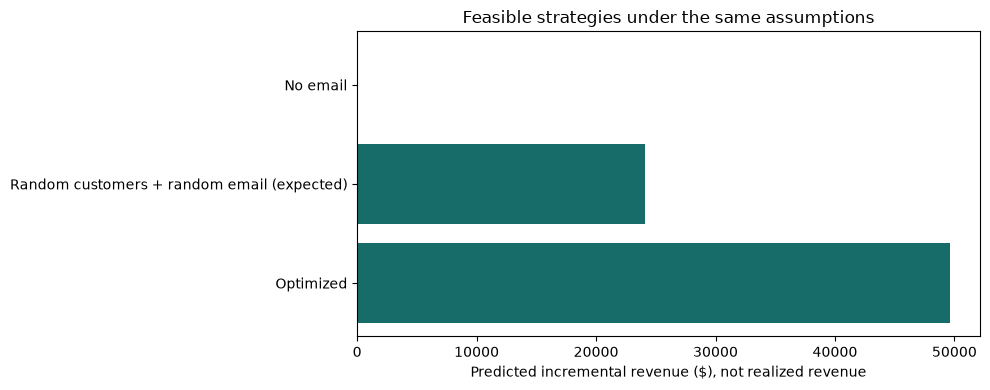

In [5]:
benchmarks = comparison_table(cohort, summary)
display(benchmarks)
feasible = benchmarks[benchmarks.feasible]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(feasible.strategy, feasible.revenue, color='#176b68')
ax.set_xlabel('Predicted incremental revenue ($), not realized revenue')
ax.set_title('Feasible strategies under the same assumptions')
plt.tight_layout()
fig.savefig(OUTPUT / 'strategy_comparison.png', dpi=140)
plt.show()

## 5. Budget and cost sensitivity

These are model-based planning scenarios, not repeated experiments. More budget cannot reduce the optimal predicted revenue when costs stay fixed. An unused budget is allowed when no further positive predicted effects remain. At a smaller budget the constraint is visibly binding.


,budget,contacted,allocated_cost,unused_budget,predicted_incremental_revenue
0,0.0,0,0.0,0.0,0.000000
1,100.0,1000,100.0,0.0,2949.700147
2,500.0,5000,500.0,0.0,11583.443512
3,1000.0,10000,1000.0,0.0,19487.581123
4,5000.0,50000,5000.0,0.0,49659.708342


,email_cost,contacted,allocated_cost,predicted_incremental_revenue
0,0.05,60734,3036.7,51702.172400
1,0.10,50000,5000.0,49659.708342
2,0.20,25000,5000.0,35367.253897


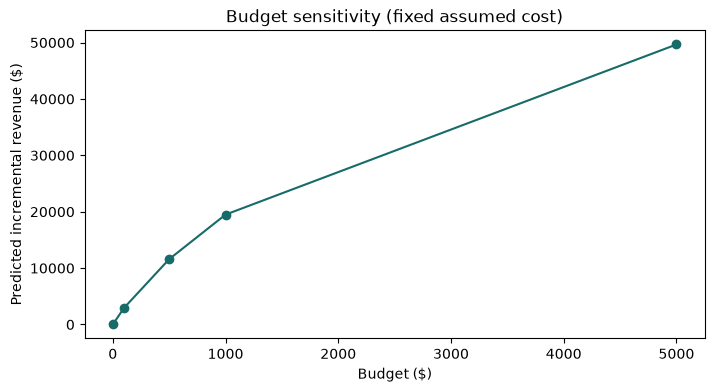

In [6]:
scenario_records = []
for scenario_budget in [0, 100, 500, 1000, 5000]:
    _, record = allocate_email(cohort, scenario_budget, EMAIL_COST)
    scenario_records.append(record)
scenarios = pd.DataFrame(scenario_records)
assert (scenarios.predicted_incremental_revenue.diff().dropna() >= -1e-8).all()
display(scenarios[['budget', 'contacted', 'allocated_cost', 'unused_budget', 'predicted_incremental_revenue']])
cost_sensitivity = pd.DataFrame([allocate_email(cohort, BUDGET, cost)[1] for cost in [0.05, 0.10, 0.20]])
display(cost_sensitivity[['email_cost', 'contacted', 'allocated_cost', 'predicted_incremental_revenue']])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(scenarios.budget, scenarios.predicted_incremental_revenue, marker='o', color='#176b68')
ax.set(xlabel='Budget ($)', ylabel='Predicted incremental revenue ($)', title='Budget sensitivity (fixed assumed cost)')
fig.savefig(OUTPUT / 'budget_sensitivity.png', dpi=140, bbox_inches='tight')
plt.show()

## 6. Independent correctness checks

For a small example, enumerate every possible action combination (no email, men’s, women’s) and check the optimizer against the true maximum. Also check zero budget, negative effects, exact cents, empty inputs and invalid costs. This verifies implementation, not the causal accuracy of the input scores.

In [7]:
def brute_force(rows, budget, cost):
    values = rows[['spend_mens', 'spend_womens']].to_numpy()
    best = 0.
    for actions in itertools.product([0, 1, 2], repeat=len(rows)):
        if sum(a != 0 for a in actions) * cents(cost, 'Cost') <= cents(budget, 'Budget'):
            value = sum(values[i, a-1] for i, a in enumerate(actions) if a)
            best = max(best, value)
    return best
assert np.isclose(toy_summary['predicted_incremental_revenue'], brute_force(toy, .2, .1))
assert allocate_email(toy, 0, .1)[1]['contacted'] == 0
assert allocate_email(toy, .09, .1)[1]['contacted'] == 0
assert allocate_email(toy, .3, .1)[1]['contacted'] == 3
assert allocate_email(toy.iloc[:0], 5, .1)[1]['contacted'] == 0
negative = toy.copy()
negative[['spend_mens', 'spend_womens']] = -1.
assert allocate_email(negative, 5, .1)[1]['contacted'] == 0
for budget, cost in [(-1, .1), (1, 0), (1, .001), (float('nan'), .1)]:
    try:
        allocate_email(toy, budget, cost)
    except (ValueError, ArithmeticError):
        pass
    else:
        raise AssertionError('Invalid money accepted')
print('Exhaustive optimum, budget, empty-input and invalid-input checks passed.')

Exhaustive optimum, budget, empty-input and invalid-input checks passed.


## 7. Save reproducible outputs and dashboard evidence

CSV includes every eligible row, including No E-Mail choices and reasons. The dashboard can recompute the same equal-cost optimum when the user changes budget, cost or population. It does not run SciPy inside the browser; the saved default is independently checked against SciPy here. Week 4 can expose the Python solver through a REST API.


In [8]:
allocation.to_csv(OUTPUT / 'allocation.csv', index=False)
benchmarks.to_csv(OUTPUT / 'strategy_comparison.csv', index=False)
scenarios.to_csv(OUTPUT / 'budget_scenarios.csv', index=False)
cost_sensitivity.to_csv(OUTPUT / 'cost_sensitivity.csv', index=False)
# Small cross-language fixtures let Node tests verify the independent browser implementation.
fixtures = []
for population, budget in [('test', 0), ('test', 100), ('test', 1000), ('all', 5000)]:
    population_rows = scores if population == 'all' else scores.loc[scores.split == 'test']
    planned, evidence = allocate_email(population_rows, budget, EMAIL_COST)
    fixtures.append({'population': population, 'summary': evidence,
                     'selected_ids': sorted(planned.loc[planned.recommended_action != 'No E-Mail', 'customer_id'].tolist())})
artifact = {'summary': summary, 'benchmarks': benchmarks.to_dict('records'),
            'scenarios': scenarios.to_dict('records'), 'cost_sensitivity': cost_sensitivity.to_dict('records'),
            'raw_sha256': raw_hash, 'scores_sha256': hashlib.sha256(score_path.read_bytes()).hexdigest(),
            'report_sha256': hashlib.sha256((PUBLIC / 'report.json').read_bytes()).hexdigest(),
            'scipy_version': scipy.__version__, 'objective': 'predicted incremental spending',
            'cost_assumption': 'Equal fixed cost for both email types; integer cents.',
            'fixtures': fixtures,
            'limitations': ['Revenue scores have uncertain held-out ranking evidence.',
                           'Women’s visit subset stability warning remains.',
                           'All-row allocation includes training data and is descriptive.',
                           'No discount amounts, profit margins, contact addresses or realized returns are available.']}
text = json.dumps(artifact, indent=2, allow_nan=False)
(OUTPUT / 'optimization_report.json').write_text(text)
(PUBLIC / 'optimization_report.json').write_text(text)
# Compact default allocation snapshot for review; full results remain locally under results/.
columns = ['customer_id', 'split', 'recommended_action', 'allocated_cost',
           'predicted_incremental_revenue', 'predicted_revenue_less_email_cost', 'reason']
allocation[columns].to_csv(PUBLIC / 'allocation_default.csv', index=False)
print('Saved allocation, comparisons, sensitivity results and dashboard evidence.')
print(f"Default: {summary['contacted']:,} emails; cost ${summary['allocated_cost']:,.2f}; "
      f"predicted extra revenue ${summary['predicted_incremental_revenue']:,.2f}.")

Saved allocation, comparisons, sensitivity results and dashboard evidence.
Default: 50,000 emails; cost $5,000.00; predicted extra revenue $49,659.71.


## Viva explanation

“After estimating email effects, I used SciPy to choose at most one email per customer under a strict budget. I maximized predicted extra spending and verified the optimizer with an independent calculation. The dashboard shows the selected action, cost, effect and reason for every customer. These are planning predictions, not guaranteed sales. Real deployment needs a prospective experiment, real costs and valid contact identifiers.”

**Next, Week 4:** wrap scoring/optimization in a REST API, validate requests, add baseline-data drift monitoring, document its limits, and add final plain-language summaries. Drift does not automatically prove the causal effects changed. Week 3 does not send emails or deploy an API.

Reference: [SciPy linprog documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html).
